# FlowState Δ — Chapter 5.7 · Final Numerical ODE Laboratory

**Curriculum:** FlowState Research v2.0 · Chapter 5 of 72  
**Study dates:** 13–14 November 2026 · **Status:** Final laboratory; interpret results before closing Chapter 5  
**Models:** Euler (order 1), RK2 explicit midpoint (order 2), classical RK4 (order 4)

> **Goal:** reproduce the earlier scalar-ODE experiments in one research notebook, test accuracy and stability, measure computational effort, and create honest, publication-style figures. This is an educational numerical-analysis experiment, **not** evidence of improved LTC/CfC or neural-network performance.

### Laboratory plan

1. Verify the modular solvers against two different differential equations.
2. Estimate observed convergence orders at the *same* final time.
3. Plot exact and numerical hidden-state trajectories.
4. Separate **stability** from **accuracy**.
5. Compare Euler, RK2 and RK4 at a fixed dynamics-evaluation budget.
6. Optionally benchmark wall-clock time on your own machine.
7. Export metrics and write your own interpretation.

**Needed files:** `solvers.py`, `dynamics.py` and `test_solvers.py` from your existing `chap-5/`. **Dependency:** `matplotlib` for the figures; the numerical solvers themselves use Python's standard library.

## 0 · Reproducible setup

Place **this notebook inside `flowstate/chap-5/`**. Open it in JupyterLab or VS Code, select your FlowState `.venv` kernel, and run the cells in order. If required, install Matplotlib in that environment with `python -m pip install matplotlib`.

The setup searches the notebook's working directory and its `chap-5` child for the existing modules. It refuses to silently substitute any alternate solver implementations.

In [9]:
import math
import platform
import sys
import json
import time
from datetime import datetime, timezone
from pathlib import Path
from statistics import median

import matplotlib.pyplot as plt

candidates = [Path.cwd(), Path.cwd() / 'chap-5']
LAB_DIR = next((p for p in candidates if (p / 'solvers.py').exists()
                and (p / 'dynamics.py').exists()), None)
if LAB_DIR is None:
    raise FileNotFoundError(
        'Place this notebook in flowstate/chap-5/ or launch from flowstate/. '
        'Both solvers.py and dynamics.py must be present.'
    )
sys.path.insert(0, str(LAB_DIR.resolve()))

from solvers import euler_step, rk2_step, rk4_step, solve
from dynamics import decay_dynamics, exact_decay, time_dynamics, exact_time

FIG_DIR = LAB_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=True)
METHODS = {'Euler': euler_step, 'RK2': rk2_step, 'RK4': rk4_step}
print('Python:', platform.python_version())
print('Working folder:', LAB_DIR.resolve())
print('Methods:', ', '.join(METHODS))

Python: 3.12.3
Working folder: /home/pratay-karali/Desktop/flowstate/chap-5
Methods: Euler, RK2, RK4


## 1 · Why regression tests need more than one ODE

Two simple differential equations test different parts of the implementation:

**State-dependent decay:** $h'(t)=-2h(t)$, $h(0)=1$, exact $h(t)=e^{-2t}$. This uses the **state**, not the explicit time argument.

**Time-dependent growth:** $h'(t)=t$, $h(0)=0$, exact $h(t)=t^2/2$. This uses **time**, not the state. It catches midpoint/endpoint time mistakes hidden by the decay example.

RK2 checks at $t$ and $t+\Delta t/2$. RK4 checks at $t$, $t+\Delta t/2$, $t+\Delta t/2$, $t+\Delta t$.

In [2]:
assert math.isclose(rk2_step(decay_dynamics, 0.0, 1.0, 0.1), 0.82,
                    rel_tol=0.0, abs_tol=1e-12)
assert math.isclose(rk4_step(decay_dynamics, 0.0, 1.0, 0.1),
                    0.8187333333333333, rel_tol=0.0, abs_tol=1e-12)
assert math.isclose(rk2_step(time_dynamics, 0.0, 0.0, 1.0), 0.5,
                    rel_tol=0.0, abs_tol=1e-12)
assert math.isclose(rk4_step(time_dynamics, 0.0, 0.0, 1.0), 0.5,
                    rel_tol=0.0, abs_tol=1e-12)
print('PASS: four targeted RK2/RK4 regression checks')
print('Decay exact h(0.1):', exact_decay(0.1))
print('Time-dependent exact h(1):', exact_time(1.0))

PASS: four targeted RK2/RK4 regression checks
Decay exact h(0.1): 0.8187307530779818
Time-dependent exact h(1): 0.5


## 2 · Convergence order: how quickly does error shrink?

We compare every solver at **the same final time $T=1$**, starting from the **same** initial state $h_0=1$. Only the time step varies. Absolute error is $|h_{\mathrm{numeric}}(T)-h_{\mathrm{exact}}(T)|$.

With sufficiently smooth dynamics and sufficiently small steps, the expected **global** error orders are Euler $O(\Delta t)$, RK2 $O(\Delta t^2)$ and RK4 $O(\Delta t^4)$. The local errors per step are respectively $O(\Delta t^2)$, $O(\Delta t^3)$ and $O(\Delta t^5)$.

When halving the step, an experimental order estimate is

$$
\hat p=\log_2\!\left(\frac{E(\Delta t)}{E(\Delta t/2)}\right).
$$

Do not interpret $\hat p$ as a guarantee for arbitrarily large or tiny steps. Floating-point roundoff can eventually dominate at extremely small errors.

Δt       Euler error      RK2 error        RK4 error
0.2000   0.05757528324    0.01005807356    8.073139157e-05
0.1000   0.02796110084    0.002112748099   4.265193897e-06
0.0500   0.01375862865    0.0004871742655  2.45185178e-07
0.0250   0.006823126672   0.0001171438055  1.469759145e-08
0.0125   0.00339747785    2.873183892e-05  8.996432488e-10
Euler observed order (last halving): 1.0060
RK2 observed order (last halving): 2.0276
RK4 observed order (last halving): 4.0301


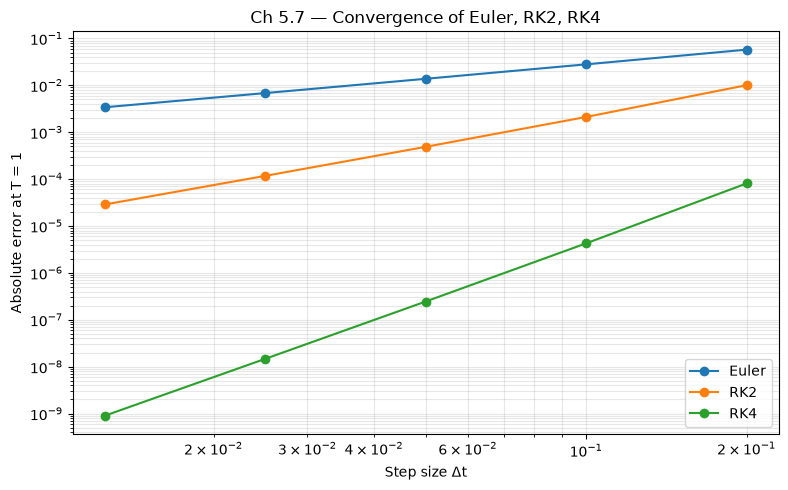

Saved: /home/pratay-karali/Desktop/flowstate/chap-5/figures/ch5_convergence.png


In [3]:
T_CONV = 1.0
STEP_SIZES = [0.2, 0.1, 0.05, 0.025, 0.0125]
convergence = {}
for name, solver in METHODS.items():
    errors = []
    for dt in STEP_SIZES:
        numerical = solve(solver, decay_dynamics, dt, T=T_CONV, h0=1.0)
        errors.append(abs(numerical - exact_decay(T_CONV)))
    convergence[name] = errors

print('Δt       Euler error      RK2 error        RK4 error')
for i, dt in enumerate(STEP_SIZES):
    print(f'{dt:<8.4f} {convergence["Euler"][i]:<16.10g} '
          f'{convergence["RK2"][i]:<16.10g} {convergence["RK4"][i]:.10g}')

orders = {}
for name, errors in convergence.items():
    if min(errors) <= 0:
        raise ValueError('Error reached zero; cannot compute log-order reliably.')
    p_last = math.log2(errors[-2] / errors[-1])
    orders[name] = p_last
    print(f'{name} observed order (last halving): {p_last:.4f}')

fig, ax = plt.subplots(figsize=(8, 5))
for name, errors in convergence.items():
    ax.loglog(STEP_SIZES, errors, marker='o', label=name)
ax.set(xlabel='Step size Δt', ylabel='Absolute error at T = 1',
       title='Ch 5.7 — Convergence of Euler, RK2, RK4')
ax.grid(True, which='both', alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'ch5_convergence.png', dpi=180)
plt.show()
print('Saved:', FIG_DIR / 'ch5_convergence.png')

**Interpretation prompt A:** Are your last-halving empirical orders approaching 1, 2, and 4? If one differs, explain whether the tested step sizes may not yet be asymptotically small or whether floating-point effects might matter. Do not simply write “all methods work.”

## 3 · Hidden-state trajectories at fixed physical times

The `solve()` helper returns only the final state. Here we write a tiny `rollout()` to retain **every** intermediate state, so we can inspect the trajectory and compare it to the exact exponential decay.

At $\Delta t=0.6$, Euler may alternate signs but still decay. Oscillation alone is not proof of instability. In addition, a stable numerical trajectory can have a large error.

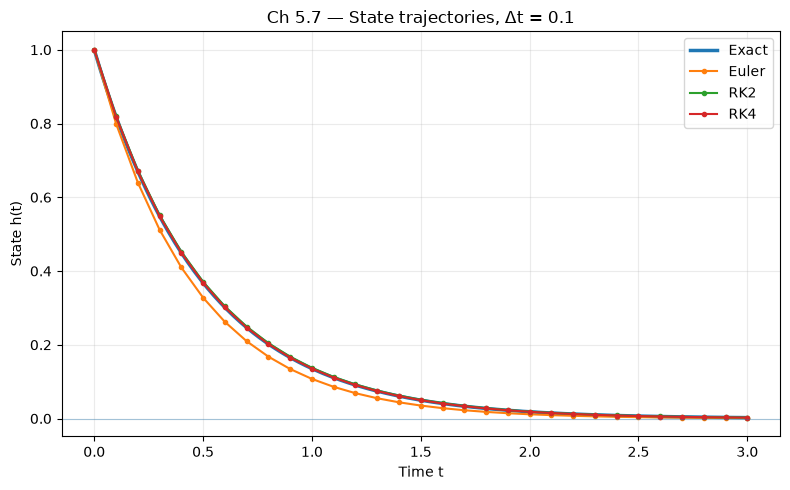

Saved: /home/pratay-karali/Desktop/flowstate/chap-5/figures/ch5_trajectory_dt_0p1.png


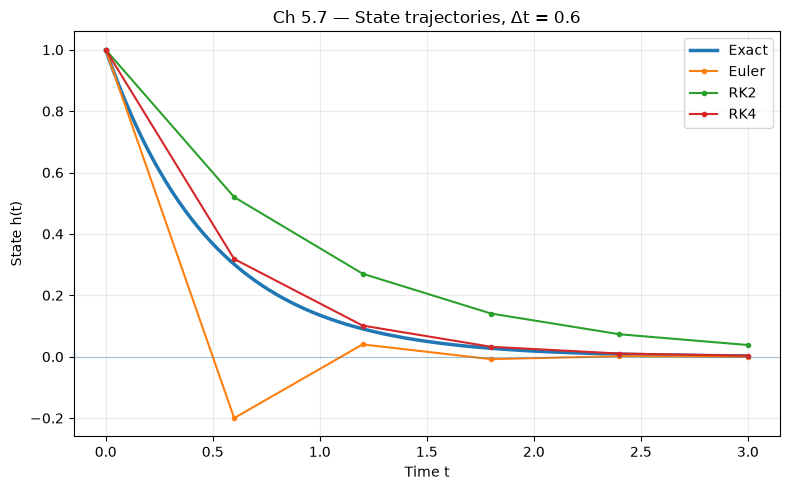

Saved: /home/pratay-karali/Desktop/flowstate/chap-5/figures/ch5_trajectory_dt_0p6.png


In [4]:
def rollout(step_fn, dynamics, dt, T, h0=1.0):
    steps = round(T / dt)
    if not math.isclose(steps * dt, T, rel_tol=0.0, abs_tol=1e-12):
        raise ValueError('Choose Δt that divides T exactly for this lab')
    ts, hs = [0.0], [h0]
    h = h0
    for i in range(steps):
        t = i * dt
        h = step_fn(dynamics, t, h, dt)
        ts.append((i + 1) * dt)
        hs.append(h)
    return ts, hs

T_TRAJ = 3.0
trajectory_summary = {}
for dt in [0.1, 0.6]:
    fig, ax = plt.subplots(figsize=(8, 5))
    dense_t = [T_TRAJ * i / 300 for i in range(301)]
    ax.plot(dense_t, [exact_decay(t) for t in dense_t],
            label='Exact', linewidth=2.5)
    for name, method in METHODS.items():
        ts, hs = rollout(method, decay_dynamics, dt, T_TRAJ)
        ax.plot(ts, hs, marker='o', markersize=3, label=name)
        trajectory_summary.setdefault(str(dt), {})[name] = {
            'final_state': hs[-1],
            'final_abs_error': abs(hs[-1] - exact_decay(T_TRAJ))
        }
    ax.axhline(0, linewidth=0.8, alpha=0.35)
    ax.set(xlabel='Time t', ylabel='State h(t)',
           title=f'Ch 5.7 — State trajectories, Δt = {dt}')
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fn = FIG_DIR / f'ch5_trajectory_dt_{str(dt).replace(".", "p")}.png'
    fig.savefig(fn, dpi=180)
    plt.show()
    print('Saved:', fn)

## 4 · Stability is not the same as accuracy

For this *linear* test problem, each explicit solver applies a multiplier $R(z)$ per step, where $z=-2\Delta t$:

- Euler: $R(z)=1+z$
- RK2: $R(z)=1+z+z^2/2$
- RK4: $R(z)=1+z+z^2/2+z^3/6+z^4/24$

The numerical state decays asymptotically when $|R(z)|<1$. The equality $|R(z)|=1$ is a boundary case (no asymptotic decay). This criterion applies to this scalar negative-real test problem; nonlinear systems and stiff systems require more analysis.

In [5]:
def stability_multiplier(method, z):
    if method == 'Euler':
        return 1 + z
    if method == 'RK2':
        return 1 + z + z**2 / 2
    if method == 'RK4':
        return 1 + z + z**2 / 2 + z**3 / 6 + z**4 / 24
    raise ValueError(method)

stability = []
print('Δt    solver   R(-2Δt)    stability       h(3)          error')
for dt in [0.1, 0.6, 1.0, 1.5]:
    for name, method in METHODS.items():
        r = stability_multiplier(name, -2 * dt)
        status = 'decays' if abs(r) < 1 else ('boundary' if abs(r) == 1 else 'diverges')
        final = solve(method, decay_dynamics, dt, T=3.0)
        error = abs(final - exact_decay(3.0))
        stability.append({'dt': dt, 'solver': name, 'R': r,
                          'status': status, 'final': final, 'error': error})
        assert math.isclose(final, r ** round(3.0/dt), abs_tol=1e-10, rel_tol=1e-10)
        print(f'{dt:<5.1f} {name:<7} {r:>9.5f}    {status:<10} {final:>12.6f}  {error:.6f}')
print('Exact at T=3:', exact_decay(3.0))

Δt    solver   R(-2Δt)    stability       h(3)          error
0.1   Euler     0.80000    decays         0.001238  0.001241
0.1   RK2       0.82000    decays         0.002597  0.000118
0.1   RK4       0.81873    decays         0.002479  0.000000
0.6   Euler    -0.20000    decays        -0.000320  0.002799
0.6   RK2       0.52000    decays         0.038020  0.035542
0.6   RK4       0.31840    decays         0.003272  0.000794
1.0   Euler    -1.00000    boundary      -1.000000  1.002479
1.0   RK2       1.00000    boundary       1.000000  0.997521
1.0   RK4       0.33333    decays         0.037037  0.034558
1.5   Euler    -2.00000    diverges       4.000000  3.997521
1.5   RK2       2.50000    diverges       6.250000  6.247521
1.5   RK4       1.37500    diverges       1.890625  1.888146
Exact at T=3: 0.0024787521766663585


**Interpretation prompt B:** Identify one case where the numerical multiplier predicts decay but the final result is still quite inaccurate. Why is that not a contradiction?

**Scope warning:** Passing these linear stability checks does not prove a solver is appropriate for stiff ODEs or learned neural dynamics.

## 5 · Equal computational budget: accuracy per NFE

A **number of function evaluations (NFE)** counts how many times a solver evaluates the dynamics function. It is a useful algorithmic-work measure—not automatically a runtime or energy-use measure.

We choose step sizes that make each method use **20 evaluations** to reach $T=1$: Euler $\Delta t=0.05$, RK2 $\Delta t=0.10$, RK4 $\Delta t=0.20$.

Method   Δt     steps    measured_NFE    estimate      abs_error
Euler   0.05  20       20              0.121576655    0.013758629
RK2     0.10  10       20              0.137448031    0.002112748
RK4     0.20  5        20              0.135416015    0.000080731


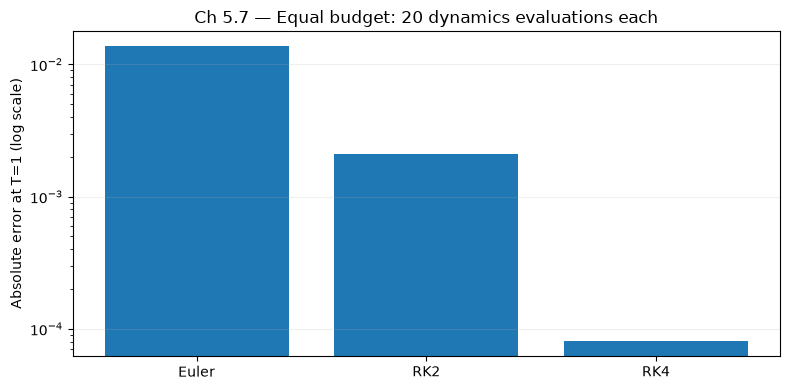

Saved: /home/pratay-karali/Desktop/flowstate/chap-5/figures/ch5_equal_nfe.png


In [6]:
class CountedDynamics:
    def __init__(self, fn):
        self.fn = fn
        self.calls = 0

    def __call__(self, t, h):
        self.calls += 1
        return self.fn(t, h)

configs = [('Euler', euler_step, 0.05),
           ('RK2', rk2_step, 0.10),
           ('RK4', rk4_step, 0.20)]

cost_results = []
print('Method   Δt     steps    measured_NFE    estimate      abs_error')
for name, method, dt in configs:
    counted = CountedDynamics(decay_dynamics)
    estimate = solve(method, counted, dt, T=1.0)
    err = abs(estimate - exact_decay(1.0))
    row = {'solver': name, 'dt': dt, 'steps': round(1.0/dt),
           'nfe': counted.calls, 'estimate': estimate, 'abs_error': err}
    cost_results.append(row)
    print(f'{name:<7} {dt:<5.2f} {row["steps"]:<8} {row["nfe"]:<15} '
          f'{estimate:.9f}    {err:.9f}')
assert all(row['nfe'] == 20 for row in cost_results)
assert cost_results[2]['abs_error'] < cost_results[1]['abs_error'] < cost_results[0]['abs_error']

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([r['solver'] for r in cost_results],
       [r['abs_error'] for r in cost_results])
ax.set_yscale('log')
ax.set(ylabel='Absolute error at T=1 (log scale)',
       title='Ch 5.7 — Equal budget: 20 dynamics evaluations each')
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig(FIG_DIR / 'ch5_equal_nfe.png', dpi=180)
plt.show()
print('Saved:', FIG_DIR / 'ch5_equal_nfe.png')

**Interpretation prompt C:** Does equal NFE imply equal elapsed time? Explain why the implementation language, loop overhead, batch sizes, and actual dynamics function cost can matter.

In the **user's earlier Ubuntu run (14 Nov 2026)**, the reported medians were Euler **5.375 µs**, RK2 **5.537 µs**, RK4 **4.876 µs** per solve, from seven batches of 2,000 repeated runs. These are **user-reported results from that session**, not results automatically reproduced by this notebook. The ranges overlapped. Do not generalize a runtime ranking from this microbenchmark.

## 6 · Optional: independently reproduce the CPU runtime microbenchmark

This measures elapsed time using `perf_counter()`, after warm-up, over seven batches. It is useful for practicing honest benchmarking, but microsecond-scale Python measurements are noisy and not representative of GPU/edge-neural-network performance.

In [7]:
def benchmark(method, dt, warmups=200, repeats=2000, batches=7):
    for _ in range(warmups):
        solve(method, decay_dynamics, dt, T=1.0)
    timings_us = []
    for _ in range(batches):
        tic = time.perf_counter()
        for _ in range(repeats):
            solve(method, decay_dynamics, dt, T=1.0)
        timings_us.append((time.perf_counter() - tic) * 1e6 / repeats)
    return {'median_us': median(timings_us),
            'min_us': min(timings_us), 'max_us': max(timings_us)}

runtime_results = {}
print('Solver    median_us   min_us    max_us')
for name, method, dt in configs:
    results = benchmark(method, dt)
    runtime_results[name] = results
    print(f'{name:<7}   {results["median_us"]:>8.3f}   '
          f'{results["min_us"]:>7.3f}   {results["max_us"]:>7.3f}')
print('NOTE: these are timings from THIS kernel/machine/run, not universal performance claims.')

Solver    median_us   min_us    max_us
Euler        8.099     5.643     9.478
RK2          6.742     5.749     8.182
RK4          5.424     4.939     8.755
NOTE: these are timings from THIS kernel/machine/run, not universal performance claims.


## 7 · Save experiment metadata and check consistency

The plots are saved in `chap-5/figures/`. The JSON report records the results produced by this run, Python version, and a UTC timestamp. No random seed is needed for these deterministic scalar ODE tests. The environment and code version still matter for reproducibility.

In [8]:
report = {
    'project': 'FlowState Δ',
    'chapter': '5.7',
    'generated_at_utc': datetime.now(timezone.utc).isoformat(),
    'python_version': platform.python_version(),
    'platform': platform.platform(),
    'equation': 'dh/dt = -2h, h(0)=1',
    'convergence': {'T': T_CONV, 'dt_values': STEP_SIZES,
                    'errors': convergence, 'empirical_order_last_halving': orders},
    'stability_at_T3': stability,
    'equal_nfe_at_T1': cost_results,
    'runtime_us_per_solve': runtime_results,
    'limitations': [
        'Single scalar linear ODE; not a neural ODE benchmark',
        'Fixed-step explicit solvers; no adaptive-step or stiff-ODE tests',
        'Equal NFE is not equal hardware runtime or energy',
        'Microsecond Python timings are environment-sensitive'
    ],
}
report_path = FIG_DIR / 'ch5_lab_results.json'
report_path.write_text(json.dumps(report, indent=2), encoding='utf-8')
assert len(convergence) == 3 and len(cost_results) == 3
print('Saved:', report_path)
print('Figures:', *sorted(p.name for p in FIG_DIR.glob('ch5_*.png')), sep='\n - ')

Saved: /home/pratay-karali/Desktop/flowstate/chap-5/figures/ch5_lab_results.json
Figures:
 - ch5_convergence.png
 - ch5_equal_nfe.png
 - ch5_trajectory_dt_0p1.png
 - ch5_trajectory_dt_0p6.png


## 8 · Researcher's Interpretation

### A. Numerical Accuracy

The convergence experiment produced empirical orders of **1.006 for Euler, 2.028 for RK2, and 4.030 for RK4**, estimated from the two smallest tested step sizes. These results closely match the theoretical global convergence orders of 1, 2, and 4, respectively. RK4 demonstrated the steepest slope on the log-log error plot because its weighted intermediate slope evaluations cancel more lower-order approximation errors. Consequently, its error decreased substantially faster than Euler's or RK2's as the step size was reduced. These observations support the predicted convergence rates for our smooth exponential-decay equation under sufficiently small step sizes and suitable numerical stability conditions. However, the same accuracy behavior cannot be assumed for every differential equation, particularly stiff or nonsmooth systems.

### B. Stability vs Accuracy

The stability experiments demonstrated that **numerical stability and numerical accuracy are distinct properties**. At Δt = 0.6, RK2 had a stability multiplier of 0.52, indicating that its numerical trajectory decays because the multiplier's absolute value is less than one. Nevertheless, its final value at T = 3 was approximately 0.038020, compared with the exact value of 0.002479, resulting in an absolute error of approximately **0.035542**. This is an example of a stable yet inaccurate numerical approximation. In contrast, Euler at Δt = 1.5 had a multiplier of −2, producing the trajectory 1 → −2 → 4, which diverges in magnitude instead of decaying. These findings establish that a bounded, decaying numerical trajectory does not necessarily reproduce the true system dynamics accurately.

### C. Accuracy Versus Computation

At an equal budget of **20 Number of Function Evaluations (NFE)**, RK4 achieved the lowest absolute error, approximately 0.000080731, compared with 0.002112748 for RK2 and 0.013758629 for Euler. Thus, RK4 achieved approximately **26.2 times lower error than RK2 and 170.4 times lower error than Euler** in this particular experiment. The CPU benchmark also reported median execution times of 5.375 µs for Euler, 5.537 µs for RK2, and 4.876 µs for RK4, although these small differences should not be interpreted as universal runtime advantages. Equal NFE does not guarantee equal execution time because numerical solvers also involve loop overhead, intermediate calculations, memory access and implementation-specific costs. When the dynamics function is a neural network, model architecture, tensor dimensions, batching and hardware execution can further influence computational efficiency. Therefore, evaluating numerical accuracy, NFE and actual runtime together is necessary before identifying an efficient integration strategy.

### D. Limitations and Next Research Step

Our experiments used a simple, scalar, linear and non-stiff differential equation with a known analytical solution, which limits the generalizability of the results. They did not evaluate higher-dimensional coupled dynamics, stiff differential equations, nonlinear learned systems or irregular input sequences. Furthermore, the runtime measurements were performed using a lightweight Python dynamics function, rather than an actual neural network, so the observed timing relationships may not hold for realistic model inference. Before making efficiency claims about Liquid Time-Constant (LTC) or Closed-form Continuous-time (CfC) networks, we would need controlled comparisons using implemented neural architectures, matched datasets, comparable model capacities and consistent hardware configurations. These experiments should measure prediction quality, numerical error where a suitable reference exists, wall-clock latency, peak memory, NFE where applicable, and training stability across repeated trials. Future FlowState research should also examine whether solver selection affects long-term state retention, robustness and edge-device efficiency under realistic computational constraints.

### Final Chapter 5 Closure Checklist

- [ ] All notebook cells verified from a fresh kernel without manually modifying `solvers.py`.
- [x] Seven regression tests passed, including decay and explicit-time dynamics.
- [x] Convergence, trajectory and equal-NFE plots generated and saved.
- [x] Stability-versus-accuracy cases analyzed using the measured values and numerical multipliers.
- [x] Equal-NFE comparison and CPU benchmark limitations documented.
- [ ] Results JSON and final README checked for consistency with the notebook outputs.
- [ ] Intended code, tests, notebook, figures and documentation committed to GitHub.

**Overall conclusion:** Chapter 5 provides an experimentally supported foundation in numerical integration, convergence, stability and computational efficiency. The results demonstrate the importance of selecting numerical methods according to both mathematical behavior and computational constraints, while avoiding unsupported claims about untested neural architectures.

**Next in the fixed FlowState curriculum:** Complete publication checks, review the relevant Signals & Systems prerequisites, and begin **Chapter 6 — Liquid Time-Constant Networks**.